# CX-101 Cellular Assay — Development of a Data Processing and Analysis Pipeline 

Fictional experiment:
A concentration-response experiment investigating the effect of a fictional compound on intracellular calcium levels in cultured human muscle cells.
A newly identified compound is being investigated for its effect on intracellular calcium concentration in cultured human muscle cells.

The lab performs a concentration-response experiment.


* Compound: CX-101 (fictional)
* Cell type: cultured human skeletal muscle cells
* Concentrations: 0, 0.1, 1, 10, 100 nM, 1 µM
* Several biological/technical replicates
* Negative control: vehicle-treated cells
* Positive control: something known to induce a calcium response
* Measurement: intracellular calcium signal

Q: Does exposure to CX-101 produce a concentration-dependent change in intracellular calcium, and how reliable is the resulting dataset?


Pipeline:
Validation → cleaning → QC → statistical analysis → visualization → automated PDF report.

Input:
Messy Excel/CSV files containing experimental measurements, controls and replicates.

Output:
A reproducible analysis package plus a professional scientific report.


**For now, this notebook serves the development of the general framework for data cleaning and QC.**

## modules

In [23]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, re
from pathlib import Path
%matplotlib inline

## Input

In [2]:
data_path = "../data/"

In [4]:
# --------------------------------------------------------------------------- #
# Name / unit mappings
# --------------------------------------------------------------------------- #
# Keys are compared after normalisation (strip, lower-case, spaces/hyphens -> "_").
COLUMN_MAPPING = {
    "experiment_date": "date",
    "batch_id": "batch",
    "plate": "plate_id",
    "well_position": "well",
    "compound_name": "compound",
    "conc": "concentration",
    "concentration_unit": "unit",
    "replicate_id": "replicate",
    "rep": "replicate",
    "response_rfu": "rfu",
}

# Keys: lower-case, all non-alphanumerics removed ("CX-101", "cx 101" -> "cx101").
COMPOUND_MAPPING = {
    "cx101": "CX-101",
    "vehicle": "Vehicle",
    "ionomycin": "Ionomycin",
}

# Keys: lower-case; both micro sign (U+00B5) and Greek mu (U+03BC) are replaced by "u".
UNIT_MAPPING = {"nm": "nM", "um": "µM"}
UNIT_TO_NM = {"nM": 1.0, "µM": 1000.0}

REQUIRED_COLUMNS = (
    "batch", "plate_id", "well", "compound", "concentration", "unit", "replicate", "rfu",
)

LOG_COLUMNS = ["source_file", "source_row", "field", "change_type",
               "old_value", "new_value"]
CANONICAL_ORDER = ["source_file", "source_row", "date", "plate_id", "well",
                   "replicate", "compound", "concentration", "unit", "rfu", "notes",
                   "concentration_raw", "unit_raw"]

In [20]:
def _fmt(x) -> str:
    if x is None or pd.isna(x):
        return "<missing>"
    #float instead of np.floating would be fine for the data here
    return f"{x:g}" if isinstance(x, (float, np.floating)) else str(x)


def normalize_column_names(columns) -> list[str]:
    return [re.sub(r"[\s\-]+", "_", str(c).strip().lower()) for c in columns]
    
# eventually turn this into a class 
def standardize_data(raw_batch: pd.DataFrame , source_file: str):

    def _apply(df, col, new, change_type, log):
        old = df[col].copy()
        # recording the exact changes
        o, n = old.map(_fmt), new.map(_fmt)
        changed = o.ne(n)
        # changes that only remove leading/trailing blanks are invisible in a log: say so
        trimmed = changed & o.str.strip().eq(n)
        # all the changes excluding white space trimming
        other = changed & ~trimmed
        # after recording the changes replace col in df with new adapted entry
        df[col] = new
        _log(df, other, col, change_type, o, n, log)
        _log(df, trimmed, col, "whitespace_trimmed", "'" + o + "'", "'" + n + "'", log)


    def _log(df, mask, field, change_type, old, new, log):
        for idx in df.index[mask.fillna(False)]:
            log.append(dict(source_file=df.at[idx, "source_file"],# batch=df.at[idx, "batch"],
                            source_row=int(df.at[idx, "source_row"]), field=field,
                            change_type=change_type, old_value=old.at[idx],
                            new_value=new.at[idx]))

        
    df = raw_batch.copy()   
    log: list[dict] = []   

    # preserve the input row identifier and source file before concatenating
    df["source_file"] = source_file
    df["source_row"] = np.arange(len(df)) + 2 # make sure it matches the indexing schema used in Excel
    
    # columns
    original_columns = list(raw_batch.columns)
    # standardize names and map them to the canonical schema
    df.columns = (
        df.columns.str.strip().str.lower().str.replace(" ", "_")
    )
    df = df.rename(columns=COLUMN_MAPPING)
        
    # mapped = [COLUMN_MAPPING.get(n, n) for n in normalize_column_names(original_columns)]
    # df.columns = mapped  + ["source_file", "source_row"]
    
    for old, new in zip(original_columns, df.columns):
        if old != new:
            log.append(dict(
                source_file=source_file,
                source_row=None,
                field="column_name",
                change_type="column_renaming",
                old_value=str(old),
                new_value=new,
            ))
            
    df["batch"] = pd.to_numeric(df["batch"], errors="coerce").astype("Int64")
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    
    # identifiers 
    # add for completeness
    plate_id = df["plate_id"].astype("string").str.strip().str.upper()
    _apply(df, "plate_id", plate_id, "identifier_standardization", log)
    well = df["well"].astype("string").str.strip().str.upper()
    _apply(df, "well", well, "identifier_standardization", log)
    rep = pd.to_numeric(df["replicate"], errors="coerce").round().astype("Int64")
    _apply(df, "replicate", rep, "type_standardization", log)

    
    # compound names 
    raw_compound = df["compound"].astype("string")
    key = raw_compound.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    mapped_c = key.map(COMPOUND_MAPPING)
    new_compound = mapped_c.fillna(raw_compound.str.strip())
    _apply(df, "compound", new_compound, "compound_standardization", log)

    
    # concentration + unit -> nM 
    old_conc, old_unit = df["concentration"].copy(), df["unit"].copy()
    df["concentration_raw"], df["unit_raw"] = old_conc, old_unit

    ukey = (old_unit.astype("string").str.strip()
            # be sure to capture both, micro sign and Greek mu, in case this is wrong in xslx file
            .str.replace("µ", "u").str.replace("μ", "u").str.lower())
    canonical = ukey.map(UNIT_MAPPING)
    num = pd.to_numeric(old_conc, errors="coerce")
    factor = pd.to_numeric(canonical.map(UNIT_TO_NM), errors="coerce")
    new_conc = (num * factor).round(9)          

    # map where unit was converted
    converted = new_conc.notna() & (
        old_conc.map(_fmt).ne(new_conc.map(_fmt)) | old_unit.map(_fmt).ne("nM"))
    _log(df, converted, "concentration", "unit_conversion",
              old_conc.map(_fmt) + " " + old_unit.map(_fmt),
              new_conc.map(_fmt) + " nM", log)
    
    # log nan in conc and unit
    bad_num = num.isna() & old_conc.notna()
    _log(df, bad_num, "concentration", "invalid_concentration_set_missing",
              old_conc.map(_fmt), new_conc.map(_fmt), log)
    bad_unit = canonical.isna() & num.notna()
    _log(df, bad_unit, "unit", "invalid_unit_concentration_set_missing",
              old_unit.map(_fmt), pd.Series("<missing>", index=df.index), log)

    df["concentration"] = new_conc
    df["unit"] = pd.Series("nM", index=df.index, dtype="string").where(new_conc.notna())

    
    # measurement 
    # no QC yet, only log what has changed
    rfu = pd.to_numeric(df["rfu"], errors="coerce")
    _log(df, rfu.isna() & df["rfu"].notna(), "rfu", "invalid_rfu_set_missing",
              df["rfu"].map(_fmt), rfu.map(_fmt), log)
    df["rfu"] = rfu

    cols = [c for c in CANONICAL_ORDER if c in df.columns]
    cols += [c for c in df.columns if c not in cols]
    return df[cols], pd.DataFrame(log, columns=LOG_COLUMNS)

In [34]:
def find_batch_files(input_dir, pattern: str = "CX101_batch_*_raw.*") -> list[Path]:
    files = sorted(Path(input_dir).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No files matching {pattern!r} in {input_dir}")
    return files

def read_raw_data(path) -> pd.DataFrame:
    if path.suffix.lower() in (".xlsx", ".xlsm", ".xls"):
        return pd.read_excel(path, sheet_name=0)
    raise ValueError(f"Unsupported file type: {path}")


In [42]:
def standardize_files(files: list[Path]):
    """Read, validate and standardise several raw files into one table + one log."""
    frames, logs = [], []
    for f in files:
        d, lg = standardize_data(read_raw(f), source_file=Path(f).name)
        frames.append(d)
        logs.append(lg)
    df = pd.concat(frames, ignore_index=True)
    log = pd.concat(logs, ignore_index=True)
    return df, log

In [43]:
data_files = find_batch_files(data_path)
df, log_df = standardize_files(data_files)

In [83]:
log_df = log_df.copy()

log_df.loc[
    log_df["source_file"].duplicated(),
    "source_file"
] = ""

display(log_df)

log_csv = "../reports/standardization_log.csv"
log_df.to_csv(log_csv, index=False, na_rep="-")

,source_file,source_row,field,change_type,old_value,new_value
0,CX101_batch_1_raw.xlsx,NaN,column_name,column_renaming,Experiment Date,date
1,,NaN,column_name,column_renaming,Batch,batch
2,,NaN,column_name,column_renaming,Plate ID,plate_id
3,,NaN,column_name,column_renaming,Well,well
4,,NaN,column_name,column_renaming,Compound,compound
5,,NaN,column_name,column_renaming,Concentration,concentration
6,,NaN,column_name,column_renaming,Unit,unit
7,,NaN,column_name,column_renaming,Replicate,replicate
8,,NaN,column_name,column_renaming,RFU,rfu
9,,NaN,column_name,column_renaming,Notes,notes


## QC checks

In [44]:
CHECK_COLUMNS = [
    "batch", "plate_id", "well", "replicate", "compound", "concentration", "unit", "rfu"
]

In [45]:
def QC_checks(df, check_columns=CHECK_COLUMNS):
    duplicates = df[
        df.duplicated(subset=check_columns, keep="first")
    ]
    
    missing_values = df[
        df[check_columns[5:]].isna().any(axis=1)
    ]
    
    
    missing_identifiers = df[
        df[check_columns[:5]].isna().any(axis=1)
    ]
    return duplicates, missing_identifiers, missing_values

# find iqr outliers per condition
def flag_iqr_outliers(df, column="rfu", min_n=4):
    group_cols = ["batch", "compound", "concentration"]

    def flag_group(group):
        values = group[column]
        flagged = pd.Series(False, index=group.index)

        # IQR is unstable with very small groups
        if values.notna().sum() < min_n:
            return flagged

        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        flagged = values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
        return flagged.fillna(False)

    return (
        df.groupby(group_cols, group_keys=False)
          .apply(flag_group)
          .reindex(df.index, fill_value=False)
    )



In [46]:
duplicates, missing_identifiers, missing_values = QC_checks(df)

potential_rfu_outlier = flag_iqr_outliers(df)
rfu_outlier_rotrimmed = df.loc[potential_rfu_outlier].copy()


## QC Summary


In [47]:
qc_results = [missing_values, duplicates, missing_identifiers, rfu_outlier_rotrimmed]

In [48]:
checks = ["Missing values", "Duplicate observations", "Missing identifiers", "Potential RFU outliers"]
actions = ["Flag & exclude from response analysis", "Remove confirmed duplicate", "Flag", "Review"]
incidents = []
rotrimmed = []
for i, result in enumerate(qc_results):
    incidents.append(result.__len__())
    _rotrimmed = []
    for r in zip(result["batch"], result["source_row"]):

        _rotrimmed.append(r)
    rotrimmed.append(_rotrimmed)

In [49]:
qc_summary = {
    "Check": checks,
    "# Incident": incidents,
    "Batch & Source Row": rotrimmed,
    "Action": actions
}


In [50]:
df_qc = pd.DataFrame.from_dict(qc_summary)

In [51]:
df_qc

,Check,# Incident,Batch & Source Row,Action
0,Missing values,1,"[(1, 19)]",Flag & exclude from response analysis
1,Duplicate observations,1,"[(1, 44)]",Remove confirmed duplicate
2,Missing identifiers,1,"[(3, 37)]",Flag
3,Potential RFU outliers,11,"[(1, 15), (1, 17), (2, 2), (2, 6), (2, 12), (2...",Review


In [52]:
fn_qc_summary = "../reports/qc_summary.csv"
df_qc.to_csv(fn_qc_summary, index=False)

## Analysis

In [57]:
# exclude potential rfu outliers from analysis
exclude_rfu_outliers = True
if exclude_rfu_outliers:
    df_excl_outliers = df[~potential_rfu_outlier]
    analysis_df = df_excl_outliers.drop_duplicates(subset=CHECK_COLUMNS, keep="first").copy()
else:
    analysis_df = df.drop_duplicates(subset=CHECK_COLUMNS, keep="first").copy()

analysis_df = analysis_df.dropna(subset=["rfu"]).copy()


print("Raw df:", len(df))
print("Analysis df - trimmed:", len(analysis_df))
print("Excluded from analysis:", len(df) - len(analysis_df))

Raw df: 127
Analysis df - trimmed: 114
Excluded from analysis: 13


### descriptive statistics

In [58]:
summary = (analysis_df.groupby(["compound", "concentration"], dropna=False)["rfu"]
           .agg(n="count", mean="mean", std="std")
           .reset_index()
          )

# add standard error of the mean and coefficient of variation
summary["sem"] = summary["std"] / np.sqrt(summary["n"])
summary["cv_percent"] = summary["std"] / summary["mean"] * 100

display(summary)

,compound,concentration,n,mean,std,sem,cv_percent
0,CX-101,0.1,15,114.320667,8.143496,2.102642,7.123381
1,CX-101,1.0,16,134.355000,4.882091,1.220523,3.633725
2,CX-101,10.0,17,170.085882,8.623387,2.091479,5.070019
3,CX-101,100.0,16,216.023750,8.824342,2.206085,4.084894
4,CX-101,1000.0,19,239.846316,12.685773,2.910316,5.289125
5,Ionomycin,1000.0,15,248.818667,7.574817,1.955809,3.044312
6,Vehicle,0.0,16,99.736875,6.435229,1.608807,6.452206


### Visualise

First normalize to  vehicle -> account for background noise

For an exploratory visualization:

**response (% vehicle) = RFU / mean vehicle RFU × 100**



In [59]:
vehicle_mean = (summary.loc[summary["compound"] == "Vehicle", "mean"]).to_numpy()

In [60]:
vehicle_mean = analysis_df.loc[
    analysis_df["compound"].eq("Vehicle"),
    "rfu"
].mean()

In [61]:
analysis_df["response_pct_vehicle"] = analysis_df["rfu"] / vehicle_mean * 100
normalized_summary = (analysis_df.groupby(["compound", "concentration"], dropna=False)["response_pct_vehicle"]
           .agg(n="count", mean="mean", std="std")
           .reset_index()

        )
normalized_summary["sem"] = normalized_summary["std"] / np.sqrt(normalized_summary["n"])
display(normalized_summary)

,compound,concentration,n,mean,std,sem
0,CX-101,0.1,15,114.622267,8.164981,2.108189
1,CX-101,1.0,16,134.709454,4.894971,1.223743
2,CX-101,10.0,17,170.534602,8.646137,2.096996
3,CX-101,100.0,16,216.593662,8.847622,2.211906
4,CX-101,1000.0,19,240.479076,12.719240,2.917994
5,Ionomycin,1000.0,15,249.475098,7.594801,1.960969
6,Vehicle,0.0,16,100.000000,6.452206,1.613052


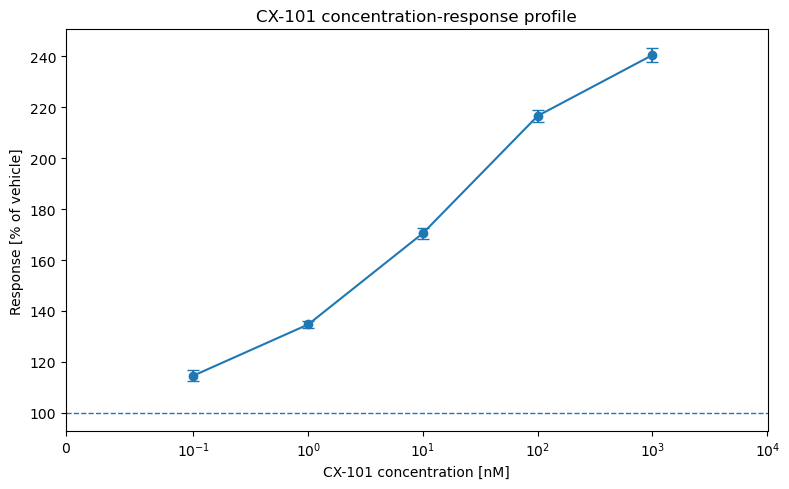

In [62]:
cx = normalized_summary[
    normalized_summary["compound"].eq("CX-101")
].sort_values("concentration")

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    cx["concentration"],
    cx["mean"],
    yerr=cx["sem"],
    marker="o",
    linestyle="-",
    capsize=4,
)
ax.axhline(100, linestyle="--", linewidth=1)
ax.set_xscale("symlog", linthresh=0.1)
ax.set(xlabel="CX-101 concentration [nM]", ylabel="Response [% of vehicle]", xlim=(0, 10100))
ax.set_title("CX-101 concentration-response profile")
plt.tight_layout()
# plt.show()
# fig_name = "cx-101_conc-respoxscale("symlog", linthresh=0.1))

### Batch-level consistency

In [63]:
batch_summary = (
    analysis_df
    .groupby(["batch", "compound", "concentration"])["rfu"]
    .agg(n="count", mean="mean", std="std")
    .reset_index()
)

batch_summary["cv_percent"] = (
    batch_summary["std"] / batch_summary["mean"] * 100
)


display(batch_summary)


,batch,compound,concentration,n,mean,std,cv_percent
0,1,CX-101,0.1,3,117.500000,1.880718,1.600611
1,1,CX-101,1.0,6,135.808333,6.509551,4.793190
2,1,CX-101,10.0,6,174.416667,3.873188,2.220653
3,1,CX-101,100.0,6,217.693333,10.307763,4.734993
4,1,CX-101,1000.0,7,239.604286,7.504503,3.132040
5,1,Ionomycin,1000.0,5,251.232000,7.324416,2.915399
6,1,Vehicle,0.0,6,97.316667,8.425705,8.658029
7,2,CX-101,0.1,6,110.523333,8.652435,7.828605
8,2,CX-101,1.0,5,132.346000,4.222538,3.190530
9,2,CX-101,10.0,6,162.225000,6.894295,4.249835


In [64]:
batch_summary[batch_summary['compound'] == 'CX-101'][batch_summary["concentration"] == 1000.0]

/var/folders/dh/r7h1rkd977v2zqb15q4h1dnr0000gp/T/ipykernel_19047/3788042309.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  batch_summary[batch_summary['compound'] == 'CX-101'][batch_summary["concentration"] == 1000.0]


,batch,compound,concentration,n,mean,std,cv_percent
4,1,CX-101,1000.0,7,239.604286,7.504503,3.132040
11,2,CX-101,1000.0,6,227.205000,4.665545,2.053452
18,3,CX-101,1000.0,6,252.770000,9.885545,3.910885


## Preliminary assessment

The pipeline can now distinguish:

- **standardization:** mechanical, traceable transformations
- **potential outliers:** observations requiring review rather than automatic deletion.
- **QC findings:** problems detected in the data
- **analysis exclusions:** observations that cannot contribute to the chosen analysis


In [65]:
assessment = []

if len(missing_values):
    assessment.append(f"{len(missing_values)} rotrimmed contain missing rfu values.")
if len(duplicates):
    assessment.append(f"{len(duplicates)} rotrimmed are involved in duplicate groups.")
if len(missing_identifiers):
    assessment.append(f"{len(missing_identifiers)} rotrimmed have missing identifiers.")
if len(rfu_outlier_rotrimmed):
    assessment.append(f"{len(rfu_outlier_rotrimmed)} potential RFU outlier(s) was (were) flagged by the IQR rule.")
else:
    assessment.append("No potential RFU outliers were flagged by the IQR rule.")

for message in assessment:
    print("•", message)


• 1 rotrimmed contain missing rfu values.
• 1 rotrimmed are involved in duplicate groups.
• 1 rotrimmed have missing identifiers.
• 11 potential RFU outlier(s) was (were) flagged by the IQR rule.


TODO

- fine tune analysis
    - condition specific QC filters
    - appropriate inferential statistics
    - better batch-effect assessment
- automated (PDF) report generation